# Quick start

**You have a forecaster. Before you trust it with real data, you want to know which kinds of series it gets right, and which ones it quietly gets wrong.**

Real data can't tell you that, because nobody knows what the best possible forecast would have been. TimeGym makes up series from recipes it knows, so it also knows the best forecast anyone could make from the same history: the answer key. A forecast is scored by how close it gets to the answer key, not to the values that came next, because those include noise that no model can predict.

In this notebook we score the simplest forecaster there is, "the future looks like the last value", and then a Ridge regression that learns from the last 24 values. Each turns out to be blind exactly where the other one sees.

## One call, one picture

Wrap a forecaster in a `Pipeline` and ask for its scorecard. The built-in last-value forecaster (`LastValueForecaster`) stands in for yours here: it predicts that every future value equals the last one it saw.

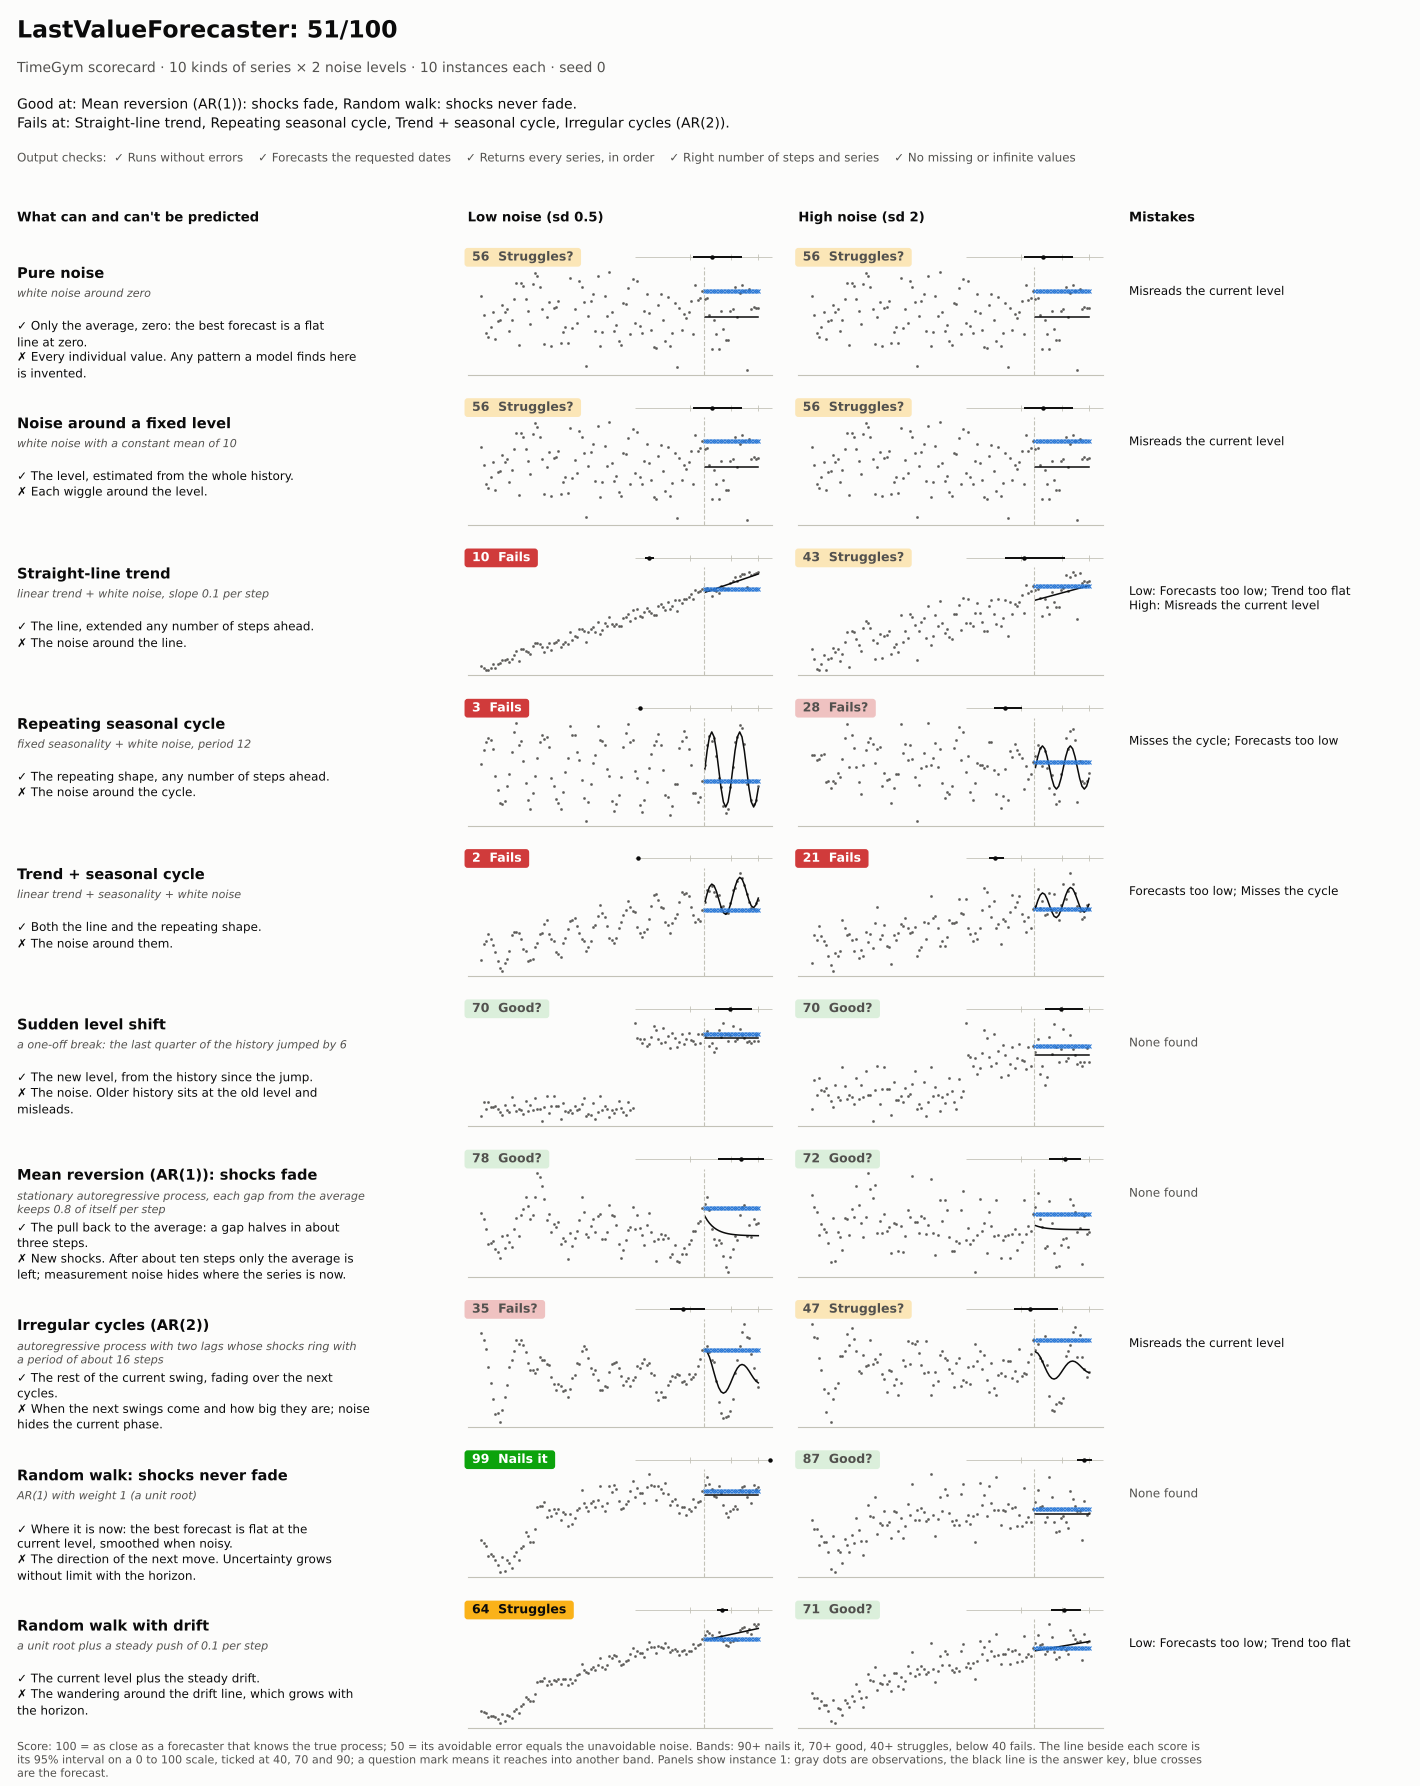

In [1]:
from timegym import LastValueForecaster, Pipeline

pipeline = Pipeline(LastValueForecaster())   # put your own forecaster here
card = pipeline.scorecard()
card

Each row is a kind of series. The left column says what a perfect forecaster could get right (✓) and what nobody can (✗). The next two columns are a low and a high noise level, each showing one of the ten series drawn for that cell: gray dots are the data, the black line is the answer key and the blue crosses are the forecast. The badge is the score out of 100. The short line beside it is the score's 95% interval, roughly where it would land on ten other series, on a 0 to 100 scale ticked at 40, 70 and 90; a question mark and a paler badge mean the interval reaches into another band, so ten draws can't settle that verdict. A score of 100 means as close as the answer key, and 50 means the avoidable error is as large as the noise nobody could predict. The bands read "Nails it" from 90, "Good" from 70, "Struggles" from 40 and "Fails" below that. The last column names the mistakes, and the line at the top says whether every forecast passed the output checks: the right dates, the right shape, no missing values.

The last-value forecaster scores 51, and the rows say why. It nails the random walk at low noise (99): when shocks never fade, the last value really is the best guess for every step ahead. It fails on the straight-line trend and the seasonal cycle at low noise (10 and 3), because a flat line can follow neither; the mistakes column says "Trend too flat" and "Misses the cycle".

Every number on the card is also in `card.table`, so the story can be checked in code:

In [2]:
baseline_table = card.table.set_index(["pattern", "noise"])
assert baseline_table.loc[("random_walk", "Low noise"), "score"] >= 90   # the last value is the answer for a random walk
assert baseline_table.loc[("seasonal", "Low noise"), "score"] < 40       # but a flat line misses every cycle

## The same scorecard, as text

For a pull request, a log or a chat message, print the scorecard: the same scores and mistakes as a Markdown table.

In [3]:
print(card)

## LastValueForecaster: 51/100

TimeGym scorecard: 10 kinds of series x 2 noise levels, 10 instances each, seed 0.

| Pattern | Low noise | High noise | Mistakes |
|---|---|---|---|
| Pure noise | 56 Struggles? | 56 Struggles? | Misreads the current level |
| Noise around a fixed level | 56 Struggles? | 56 Struggles? | Misreads the current level |
| Straight-line trend | 10 Fails | 43 Struggles? | Low: Forecasts too low; Trend too flat · High: Misreads the current level |
| Repeating seasonal cycle | 3 Fails | 28 Fails? | Misses the cycle; Forecasts too low |
| Trend + seasonal cycle | 2 Fails | 21 Fails | Forecasts too low; Misses the cycle |
| Sudden level shift | 70 Good? | 70 Good? | none found |
| Mean reversion (AR(1)): shocks fade | 78 Good? | 72 Good? | none found |
| Irregular cycles (AR(2)) | 35 Fails? | 47 Struggles? | Misreads the current level |
| Random walk: shocks never fade | 99 Nails it | 87 Good? | none found |
| Random walk with drift | 64 Struggles | 71 Good? | Low

## A contender that can learn shapes

Now a model that can learn a line or a cycle. `Pipeline(window_length=24)` cuts the history into windows of 24 consecutive values, each followed by the value that came next. scikit-learn's `Ridge` learns to predict that next value from the window (after `StandardScaler` puts the inputs on one scale), and the pipeline feeds each forecast back in as the newest value to reach 24 steps ahead.

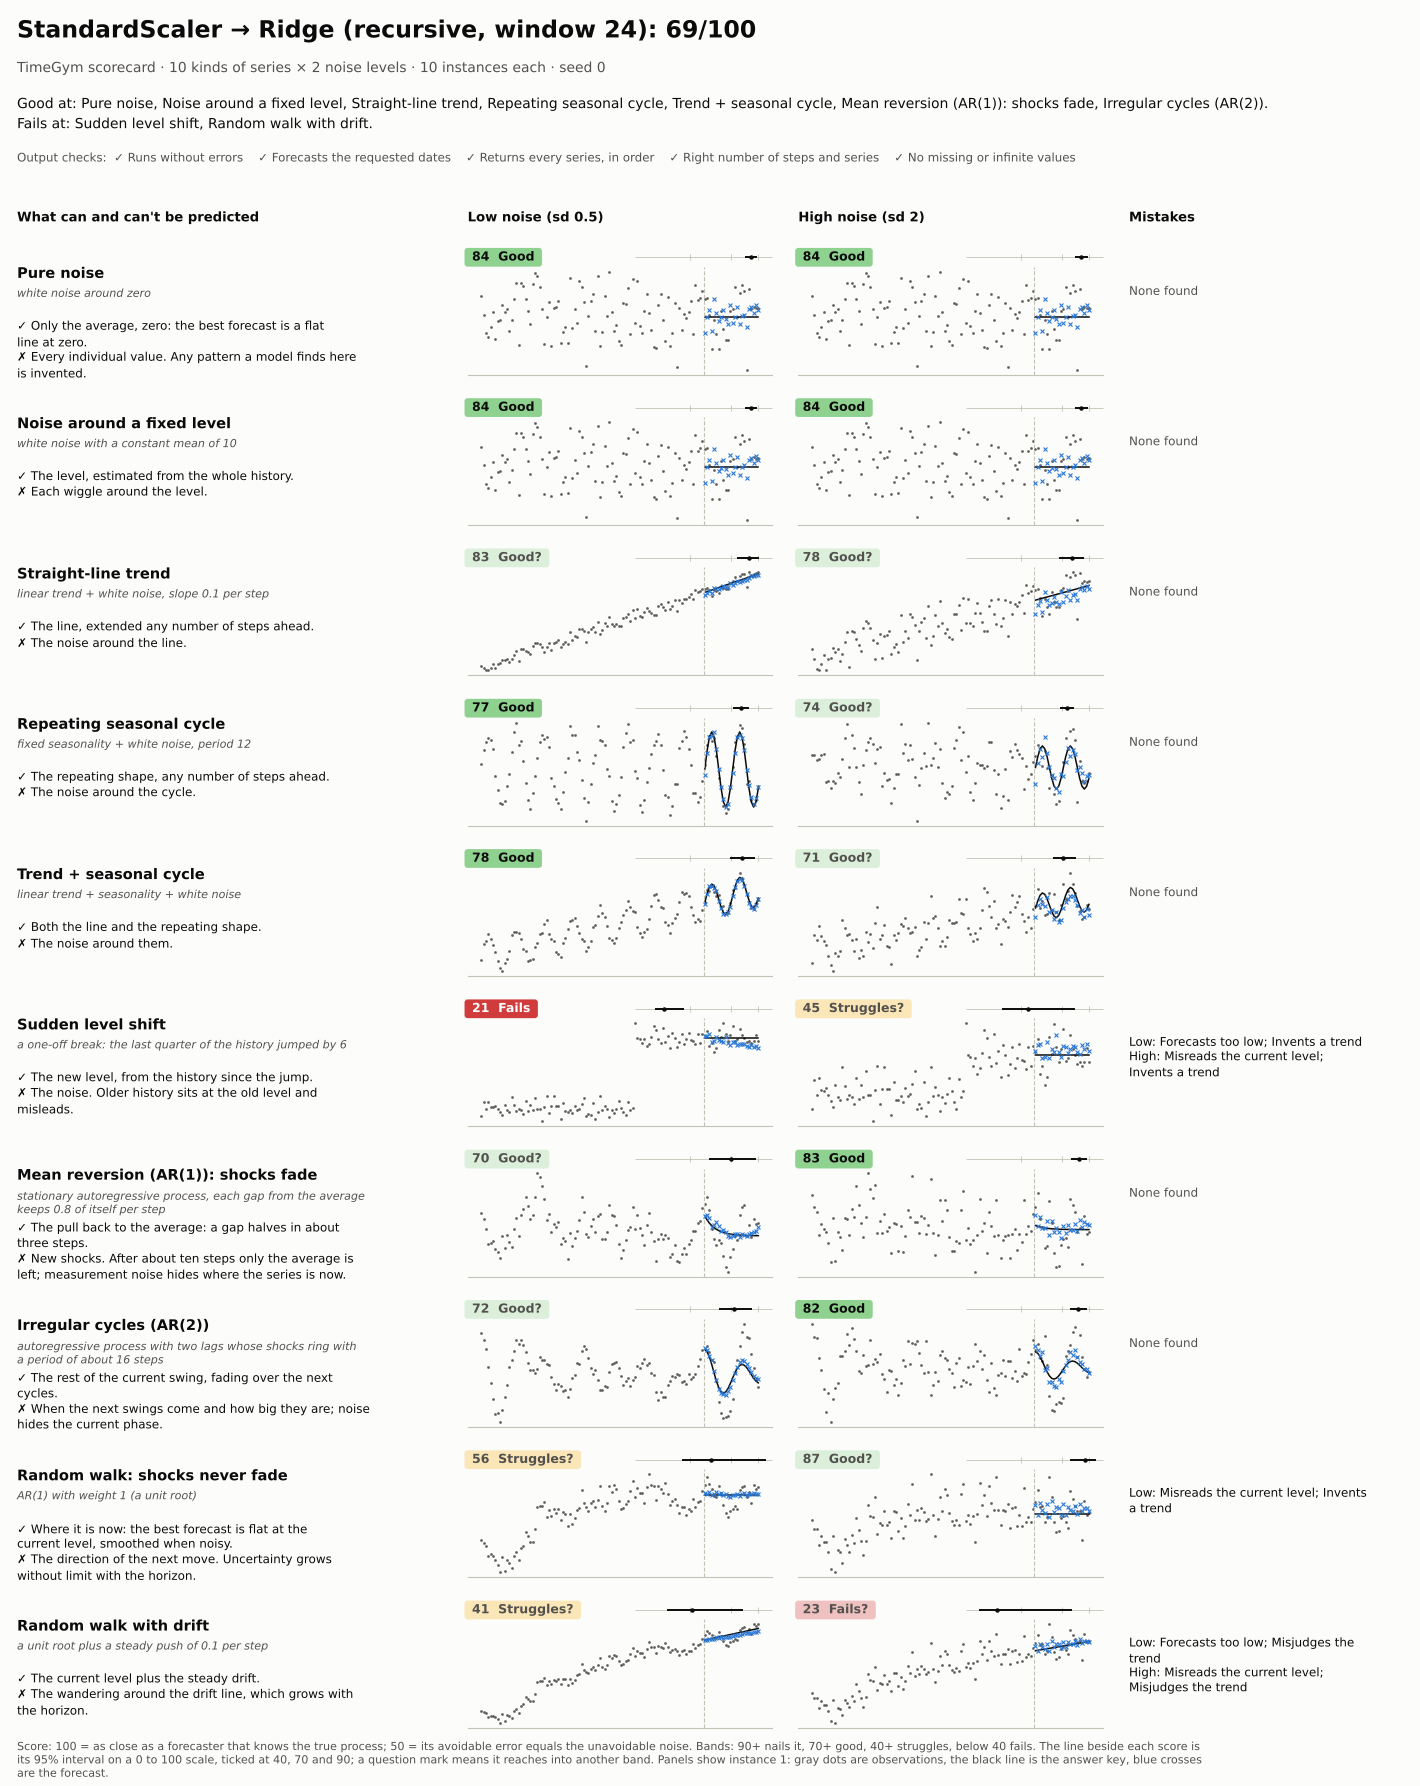

In [4]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

contender = Pipeline(window_length=24).add(StandardScaler()).add(Ridge(alpha=1.0))
ridge_card = contender.scorecard()
ridge_card

Ridge scores 69. It learned what the baseline couldn't: the trend, the seasonal cycle and the two together are "Good" at both noise levels. Now look at the bottom of the card. On the random walk at low noise Ridge drops to 56, where the baseline scored 99, and it fails on the sudden level shift (21 at low noise) and on the random walk with drift (23 at high noise). For the random walk and the level shift, the mistakes column says what goes wrong: it "invents a trend", adding a slope the answer key doesn't have.

## Side by side

Put the two models' scores next to each other, one row per kind of series and noise level:

In [5]:
import numpy as np
import pandas as pd

side_by_side = pd.DataFrame({
    "Kind of series": card.table["title"],
    "Noise": card.table["noise"],
    "Last value": card.table["score"].round().astype(int),
    "Ridge": ridge_card.table["score"].round().astype(int),
})
side_by_side["Better"] = np.select(
    [side_by_side["Ridge"] > side_by_side["Last value"], side_by_side["Ridge"] < side_by_side["Last value"]],
    ["Ridge", "Last value"], default="Tie")
side_by_side

,Kind of series,Noise,Last value,Ridge,Better
0,Pure noise,Low noise,56,84,Ridge
1,Pure noise,High noise,56,84,Ridge
2,Noise around a fixed level,Low noise,56,84,Ridge
3,Noise around a fixed level,High noise,56,84,Ridge
4,Straight-line trend,Low noise,10,83,Ridge
5,Straight-line trend,High noise,43,78,Ridge
6,Repeating seasonal cycle,Low noise,3,77,Ridge
7,Repeating seasonal cycle,High noise,28,74,Ridge
8,Trend + seasonal cycle,Low noise,2,78,Ridge
9,Trend + seasonal cycle,High noise,21,71,Ridge


In [6]:
ridge_table = ridge_card.table.set_index(["pattern", "noise"])
assert ridge_card.score > card.score   # Ridge is better overall...
assert (ridge_table.loc[("random_walk", "Low noise"), "score"]
        < baseline_table.loc[("random_walk", "Low noise"), "score"])   # ...but not on a random walk
side_by_side["Better"].value_counts()

Better
Ridge         13
Last value     6
Tie            1
Name: count, dtype: int64

Ridge is better in 13 of the 20 cells and the baseline in 6, with one tie. So neither is the better forecaster in general. If your series wander like a random walk or jump to a new level now and then, the one-line baseline is the one to beat, and Ridge doesn't beat it there.

## Why score against the answer key?

You could score against what actually happened instead: that error is in `card.table` too, as `mse`. Here is why TimeGym doesn't. Take mean reversion at high noise and measure both models both ways:

In [7]:
row = ("mean_reverting", "High noise")
yardsticks = pd.DataFrame({
    "Last value": baseline_table.loc[row, ["mse", "avoidable_mse"]],
    "Ridge": ridge_table.loc[row, ["mse", "avoidable_mse"]],
}).astype(float).rename(index={"mse": "Error against what actually happened",
                               "avoidable_mse": "Error against the answer key"})
assert yardsticks.loc["Error against what actually happened", "Last value"] < yardsticks.loc["Error against what actually happened", "Ridge"]
assert yardsticks.loc["Error against the answer key", "Ridge"] < yardsticks.loc["Error against the answer key", "Last value"]   # the two yardsticks disagree
yardsticks.round(2)

,Last value,Ridge
Error against what actually happened,8.66,9.33
Error against the answer key,2.56,1.38


Against what actually happened, the baseline looks better (8.66 against 9.33). Against the answer key, Ridge's error is about half the baseline's (1.38 against 2.56). They disagree because what actually happened includes fresh noise, and over ten short series the way that noise happened to fall is enough to flip the ranking. The answer key has no noise in it, so comparing against it measures the models, not the luck. The score is built from the same split: 100 × unavoidable / (unavoidable + avoidable).

## Look behind a score

A score is a summary over ten series. Is Ridge a little worse on every random walk, or much worse on a few? Score it on just that row and the low noise level (`patterns` and `noise_levels`), with 20 draws, and plot how the error against the answer key spreads over them:

17 of 20 draws have an error below 2; the others: 19.8, 6.7, 19.4


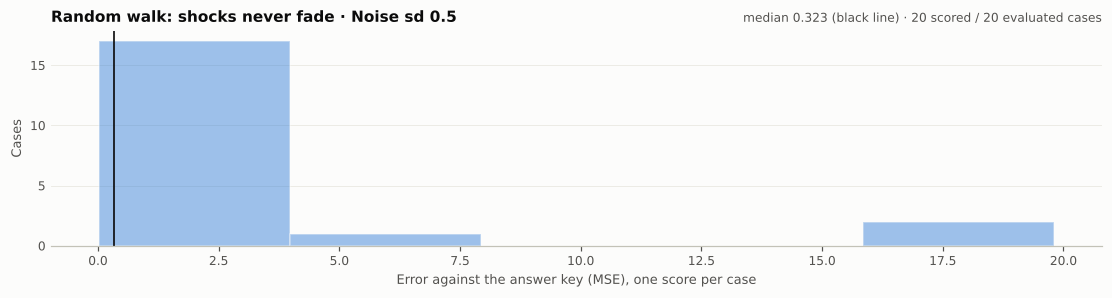

In [8]:
import matplotlib.pyplot as plt

walks = contender.scorecard(["random_walk"], noise_levels=[0.5], instances=20)
walk_errors = pd.Series([case.metrics["mean_reference_mse"] for case in walks.report.cases])
print(f"{(walk_errors < 2).sum()} of {len(walk_errors)} draws have an error below 2; "
      f"the others: {', '.join(f'{e:.1f}' for e in walk_errors[walk_errors >= 2])}")
walks.run.plot_errors()
plt.show()

Most draws sit close to the answer key and a few run away. Draw `i` uses seed `seed + i`, so `seed=5` with three instances draws seeds 5, 6 and 7 (instances 1 to 3 in the panel titles), and seed 6 is one of the runaways:

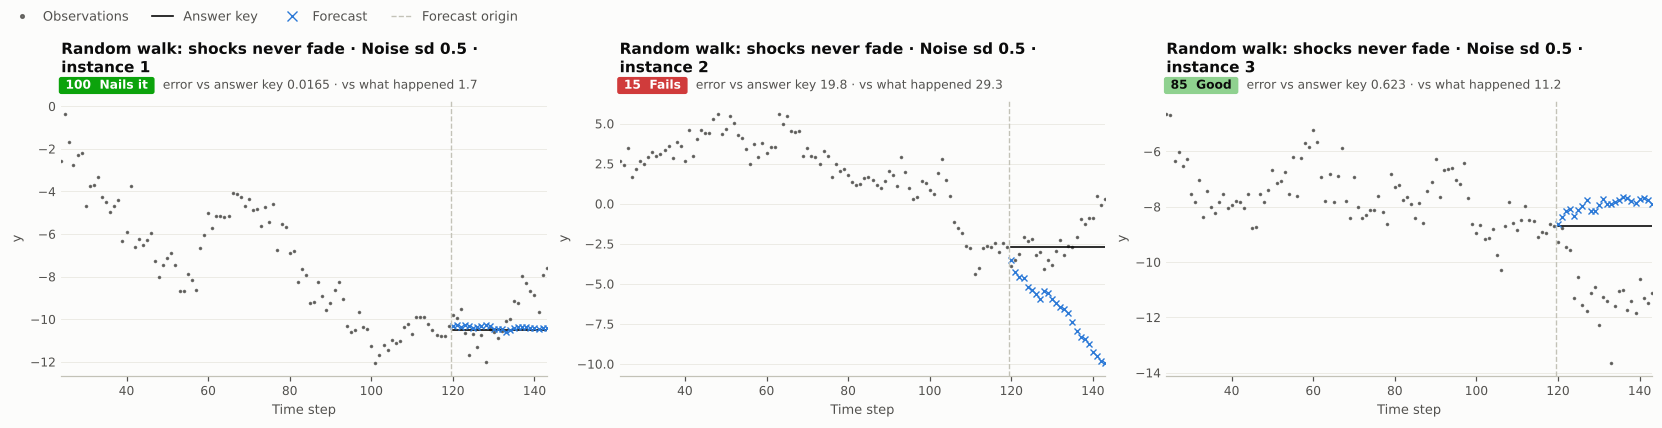

In [9]:
three_walks = contender.scorecard(["random_walk"], noise_levels=[0.5], seed=5, instances=3)
three_walks.run.plot_forecasts(figsize=(15, 3.8))
plt.show()

In instance 1 (seed 5) Ridge sits on the flat answer key and scores 100; in instance 3 (seed 7) it drifts a little above it and scores 85. In instance 2 (seed 6) it sets off downhill on a slope of its own and scores 15: that is the invented trend. Two runaways among the scorecard's ten draws, seeds 6 and 9, pull Ridge's score on this cell down to 56; the other eight alone would score in the 90s. `plot_errors(metric="mse")` draws the same histogram against what actually happened.

## Is the gap real, or the luck of the draw?

Ten draws per cell is a quick look, and a different set of draws gives a different score. Before believing a gap between two models, score them on other draws, and on more of them. `seed` picks the draws (the same seeds in every cell) and `instances` sets how many there are per cell:

In [10]:
rows = []
for instances in (10, 30):
    for seed in (0, 1000, 2000):
        rows.append({
            "Draws per cell": instances,
            "Seed": seed,
            "Last value": pipeline.scorecard(seed=seed, instances=instances).score,
            "Ridge": contender.scorecard(seed=seed, instances=instances).score,
        })
luck = pd.DataFrame(rows)
luck["Gap"] = luck["Ridge"] - luck["Last value"]
assert (luck["Gap"] > 10).all()   # Ridge stays well ahead on every set of draws
luck.round(0).astype(int)

,Draws per cell,Seed,Last value,Ridge,Gap
0,10,0,51,69,18
1,10,1000,42,63,21
2,10,2000,45,58,13
3,30,0,48,68,20
4,30,1000,44,66,22
5,30,2000,45,64,19


With 10 draws per cell, Ridge's overall score moves between 58 and 69 depending on the seed; with 30 draws it stays between 64 and 68. The gap to the baseline is 13 to 22 points in every row, so it is real. A difference of a few points between two closer models would not be, at 10 draws: compare those with 20 or 30.

Every run can be repeated from its seed. `seed=None` draws a fresh seed each time, which is what you want when tuning a model on the scorecard, because the model never sees the same series twice and can't be tuned to them. The seed it drew is kept on `card.seed`:

In [11]:
fresh = pipeline.scorecard(seed=None)
again = pipeline.scorecard(seed=fresh.seed)
assert again.score == fresh.score   # the recorded seed repeats the run exactly
print(f"seed {fresh.seed}: {fresh.score:.0f}/100")

seed 1665381082: 44/100


## Use it as a test

Scores never fail a build: TimeGym sets no pass mark for accuracy, because only you know what is good enough. Broken output does. `card.checks` lists each output check with how many forecasts passed it, and `report.assert_passed()` raises if any forecast had the wrong dates or shape or missing values, or if the model crashed. [Faults, repairs and replay](03_faults_repairs_and_replay.ipynb) shows what those failures look like.

In [12]:
ridge_card.report.assert_passed()   # raises on any broken forecast or crash
pd.DataFrame(ridge_card.checks)

,check,title,passed,failed
0,runs,Runs without errors,200,0
1,dates,Forecasts the requested dates,200,0
2,series,"Returns every series, in order",200,0
3,shape,Right number of steps and series,200,0
4,finite,No missing or infinite values,200,0


To keep the evidence, `report.to_json("report.json")` saves every case: its scenario, seed and scores, every check's verdict, the pipeline's settings, and the Python and library versions, so a failure with a built-in model can be replayed from the file alone. Here we keep the JSON in memory:

In [13]:
import json

saved = json.loads(ridge_card.report.to_json())
first = saved["cases"][0]
print(f"{len(saved['cases'])} cases; the first is {first['manifest']['kind']!r} with seed {first['seed']}")
print("Library versions:", saved["metadata"]["dependencies"])

200 cases; the first is 'white_noise' with seed 0
Library versions: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'timegym': '1.4.0'}


## Your own series

The scorecard's grid is fixed so that scores can be compared across models. To ask your own question, describe the series with `Scenario` and call `test`. Here is one the scorecard raised: would Ridge stop inventing trends on a random walk if it saw more history? Thirty draws each of 120, 480 and 1,000 steps of history, without drift and with a drift of 0.1 per step:

In [14]:
from timegym import Scenario

suite = [Scenario("random_walk", context_length=history, horizon=24, parameters={"drift": drift})
         for drift in (0.0, 0.1) for history in (120, 480, 1000)]


def error_against_answer_key(model):
    report = model.test(suite, seed=0, instances=30)
    return pd.DataFrame([{"Drift": case.manifest["parameters"]["drift"][0],
                          "History": case.manifest["context_length"],
                          "error": case.metrics["mean_reference_mse"]} for case in report.cases]
                        ).groupby(["Drift", "History"])["error"].mean()


history_errors = pd.DataFrame({"Last value": error_against_answer_key(pipeline),
                               "Ridge": error_against_answer_key(contender)})
assert history_errors.loc[(0.1, 1000), "Ridge"] < history_errors.loc[(0.1, 1000), "Last value"]   # with enough history Ridge finds the drift
history_errors.round(2)

Last value  Ridge
Drift History                   
0.0   120            0.00  16.76
      480            0.00   1.52
      1000           0.00   0.99
0.1   120            2.04  14.18
      480            2.04   2.26
      1000           2.04   1.36

More history helps Ridge a lot: on the walk without drift its error against the answer key falls from 16.76 with 120 steps to 0.99 with 1,000. It still never matches the baseline, whose error is exactly zero: with no measurement noise in these series, the last value is the answer key. With drift the story turns around. The last value can't see a slope, so its error stays at 2.04 however much history it gets, while Ridge, with 1,000 steps, learns the drift and beats it.

**What this doesn't show.** The scorecard judges point forecasts only; how good a model's uncertainty is (intervals, quantiles, samples) has its own tutorials. Its series are made up and short, 120 steps of history and 24 ahead, so a good score is a check worth passing, not proof that a model works on your data. And ten draws per cell is a quick look, not a benchmark.

## Change one thing

- `pipeline.scorecard(noise_levels=3)` adds a medium-noise column.
- Give Ridge a longer window (`window_length=48`): do the seasonal rows improve, or do the random walks get worse?
- Swap in `NaiveForecaster(strategy="mean")`, the average of the whole history, and find the rows where it beats the last value.
- Put your own model in the `Pipeline`: [Write and test a custom model](02_custom_model.ipynb) shows the two methods it needs.

How the score and the mistakes are worked out: [Scorecards and the scenario grid](../docs/api/scorecard.md).

**Next:** [Write and test a custom model](02_custom_model.ipynb).